# Hopper (medium data): BC, IQL and online fine-tuning

Planar locomotion task: a one-legged robot is rewarded for hopping forward and terminates when it falls. Dataset: Minari `mujoco/hopper/medium-v0`.

## Problem formulation

| | |
|---|---|
| **State** $s \in \mathbb{R}^{11}$ | 5 positions (torso height and angle, thigh, leg and foot angles; the forward position is excluded) and 6 velocities |
| **Action** $a \in [-1, 1]^{3}$ | torques of the thigh, leg and foot joints |
| **Reward** | $r = 1 + \dot x - 0.001\,\lVert a \rVert^2$ (constant bonus while upright) |
| **Termination** | fall: torso height, torso angle or state outside the healthy range ($d = 1$); truncation at 1,000 steps is not terminal |
| **Discount** | $\gamma = 0.99$ |

## Dataset
999,404 transitions (1,327 episodes) from a SAC agent trained for $4 \times 10^6$ steps (Minari documentation: "hops fast, in a natural looking motion, while remaining mostly upright"). 641 episodes (48%) end with a fall.

**Reward scaling.** As in the official IQL implementation, training rewards are multiplied by $1000 / (R_{\max} - R_{\min})$, where $R_{\max}$ and $R_{\min}$ are the largest and smallest episode returns in the dataset. Evaluation reports unscaled returns.

## Evaluation protocol
Episodes start from the default pose with small random noise, as in data collection. During training: `eval_episodes` episodes per seed every `eval_every` steps, with fixed environment seeds.

**Metrics.** Episode return $R = \sum_t r_t$ (unscaled) and `pct_data`, the return as a percentage of the dataset's mean episode return. Minari's MuJoCo datasets provide no random or expert reference returns, so the D4RL normalized score is not reported. The final evaluation also reports the fraction of episodes that terminated early (`fell`) and that stopped moving (`stuck`: average forward speed below 0.5 m/s over the last 100 steps).

## Offline RL setting
Offline reinforcement learning: the policy is learned from a fixed dataset $\mathcal{D} = \{(s, a, r, s', d)\}$ collected by an unknown behavior policy, without interaction with the environment. The environment is used for evaluation only. Value estimates are reliable only for actions represented in $\mathcal{D}$; the methods below avoid querying the critic on out-of-distribution actions.

## Usage
1. Copy the project folder (`offline-rl-jax/`) to Google Drive, e.g. `MyDrive/offline-rl-jax`.
2. Open this notebook in Colab with a GPU runtime (`Runtime → Change runtime type → T4 GPU`).
3. Set `PROJECT_DIR` in Section 1 if the folder is elsewhere, then run all cells.

Outputs are written to the project folder: `results/<name>/` (JSON and figures, tracked by git) and `checkpoints/<name>/` (network weights, not tracked).

`RUN_OFFLINE` (Section 2): `True` runs Part 1 and Part 2; `False` loads `checkpoints/<name>/offline.pkl` and runs Part 2 only.

## 1. Setup
Mounts Google Drive, sets the working directory and installs the simulator and dataset packages (JAX is preinstalled on Colab).

In [1]:
import os, sys, shutil
PROJECT_DIR = "/content/drive/MyDrive/offline-rl-jax"      # the project folder you uploaded to Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:                                        # running locally instead of Colab
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
if shutil.which("nvidia-smi"):
    os.environ["MUJOCO_GL"] = "egl"                        # headless rendering (only needed for videos)
print("project folder:", PROJECT_DIR)

Mounted at /content/drive
project folder: /content/drive/MyDrive/offline-rl-jax


In [2]:
!pip install -q -r requirements-colab.txt

In [3]:
import numpy as np
import jax
import matplotlib.pyplot as plt
for _m in [m for m in sys.modules if m == "offrl" or m.startswith("offrl.")]:
    del sys.modules[_m]           # always use the code currently in PROJECT_DIR (not a copy cached by an earlier run)
import offrl
from offrl import (Task, Normalizer, to_device, train_offline, EnvPool, evaluate, evaluate_final, summarize,
                   load_config, save_checkpoint, load_checkpoint, save_json, load_json, select_seed)
from offrl.algos.finetune import finetune
from offrl import plotting
print("offrl", offrl.__version__, "from", os.path.dirname(offrl.__file__))
print("JAX", jax.__version__, "| devices:", jax.devices())

offrl 0.3.0 from /content/drive/MyDrive/offline-rl-jax/offrl
JAX 0.11.1 | devices: [CudaDevice(id=0)]


## 2. Settings
Hyperparameters are read from `configs/hopper_medium.yaml`. With `RUN_OFFLINE = False`, `cfg` is taken from the checkpoint so that it matches the saved networks; `ONLINE` is always read from the config file.

In [4]:
CONFIG_FILE = "configs/hopper_medium.yaml"
RUN_OFFLINE = True     # True: train offline (Part 1), save, then fine-tune. False: load the saved offline networks.

cfg, ONLINE = load_config(CONFIG_FILE)
RESULTS_DIR = f"results/{cfg['name']}"            # small files (JSON, figures), meant for GitHub
CKPT_DIR = f"checkpoints/{cfg['name']}"           # trained networks (large, ignored by git)
if not RUN_OFFLINE:
    ck = load_checkpoint(f"{CKPT_DIR}/offline.pkl")
    cfg = ck["config"]
print("offline:", cfg)
print("online: ", ONLINE)

offline: {'name': 'hopper_medium', 'dataset_id': 'mujoco/hopper/medium-v0', 'seeds': [0, 1, 2], 'normalize_reward': True, 'batch_size': 256, 'hidden_dim': 256, 'lr': 0.0003, 'actor_lr_schedule': 'cosine', 'bc_steps': 1000000, 'iql_steps': 1000000, 'eval_every': 50000, 'eval_episodes': 10, 'final_episodes': 20, 'episodes_per_cell': 3, 'discount': 0.99, 'tau': 0.005, 'expectile': 0.7, 'beta': 3.0, 'max_weight': 100.0}
online:  {'online_steps': 300000, 'envs_per_seed': 4, 'chunk': 2000, 'updates_per_step': 1, 'explore_temperature': 1.0, 'reset_on_flip': False, 'eval_every': 50000, 'eval_episodes': 10, 'final_episodes': 20}


## 3. Data and evaluation environment
`Task` defines the dataset, the evaluation environment, the state representation and the transition labels. States are standardized with the dataset statistics (or those saved with the checkpoint), and the dataset is stored on the GPU. `evaluate_fn` is the evaluation used during training (fixed environment seeds, mean action).

In [5]:
task = Task(cfg)
raw = task.transitions()
normalizer = Normalizer(raw["states"]) if RUN_OFFLINE else Normalizer.from_state_dict(ck["normalizer"])
DATA = to_device(raw, normalizer)
pool = EnvPool(task)
N_SEEDS = len(cfg["seeds"])
print("state dim:", DATA["s"].shape[1], "| action dim:", DATA["a"].shape[1])

def evaluate_fn(pi):      # the test used during training: deterministic policy mean, eval_episodes per seed
    return evaluate(task, pi, N_SEEDS, cfg["eval_episodes"], 1000, pool, normalizer)

namespace_metadata.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

metadata.json:   0%|          | 0.00/1.59k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.26k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.62k [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Dataset mujoco/hopper/medium-v0 downloaded to /root/.minari/datasets/mujoco/hopper/medium-v0


/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


task: mujoco/hopper/medium-v0 (mujoco) | 1,327 episodes, 999,404 steps | test episodes: 1000 steps | metric: return
999,404 transitions | reward scale 0.3909 | terminal in 641 of them (0.06%)
state dim: 11 | action dim: 3


Distribution of episode returns in the dataset.

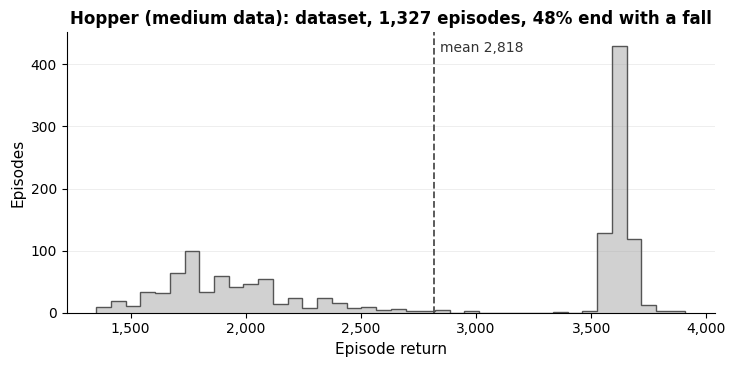

In [6]:
plotting.plot_dataset_returns(task, save_path=f"{RESULTS_DIR}/figures/dataset_returns.png")

# Part 1: Offline training

## 4. Methods

Both methods train a policy $\pi_\theta(a \mid s)$ on $\mathcal{D}$. All networks are MLPs with two hidden layers of `hidden_dim` units and ReLU activations; the policy mean is passed through $\tanh$ to the action range $[-1, 1]$.

### Behavior cloning (BC)
Regression of the dataset action (`offrl/algos/bc.py`):
$$\mathcal{L}_{BC}(\theta) = \mathbb{E}_{(s,a)\sim\mathcal{D}}\big[\,\lVert \mu_\theta(s) - a \rVert^2\,\big]$$
BC imitates the behavior policy and does not use rewards.

### Implicit Q-Learning (IQL)
Kostrikov, Nair and Levine, *Offline Reinforcement Learning with Implicit Q-Learning*, ICLR 2022 ([arXiv:2110.06169](https://arxiv.org/abs/2110.06169)); `offrl/algos/iql.py`. Three networks are updated on each batch.

**State value** by expectile regression on the target Q-values of dataset actions:
$$\mathcal{L}_V(\psi) = \mathbb{E}_{(s,a)\sim\mathcal{D}}\Big[\,L_2^{\tau}\big(\hat Q(s,a) - V_\psi(s)\big)\Big], \qquad L_2^{\tau}(u) = \lvert \tau - \mathbf{1}(u<0)\rvert\, u^2, \qquad \hat Q = \min(Q_{\bar\phi_1}, Q_{\bar\phi_2})$$
For $\tau = 0.5$ this is mean regression; for $\tau > 0.5$ (`expectile`), $V(s)$ approaches the upper range of the Q-values of in-distribution actions, an in-sample estimate of $\max_a Q(s,a)$.

**Action value** by temporal-difference learning with $V(s')$ in place of $\max_{a'} Q(s',a')$:
$$\mathcal{L}_Q(\phi_i) = \mathbb{E}_{(s,a,r,s',d)\sim\mathcal{D}}\Big[\big(r + \gamma\,(1-d)\,V_\psi(s') - Q_{\phi_i}(s,a)\big)^2\Big], \quad i = 1, 2$$
Two critics are used; their target networks are updated as $\bar\phi \leftarrow (1-\tau_t)\bar\phi + \tau_t\phi$ with $\tau_t$ = `tau`. Terminal flags $d = 1$ mark true terminations only, not time limits.

**Policy** by advantage-weighted regression:
$$\mathcal{L}_\pi(\theta) = -\,\mathbb{E}_{(s,a)\sim\mathcal{D}}\Big[\min\big(e^{\beta\,(\hat Q(s,a) - V_\psi(s))},\ 100\big)\,\log \pi_\theta(a \mid s)\Big]$$
Dataset actions are weighted by their exponentiated advantage $A = \hat Q - V$; $\beta$ (`beta`) controls the selectivity ($\beta \to 0$ recovers BC). The policy is Gaussian, $\mathcal{N}(\mu_\theta(s), \sigma^2)$, with a learned state-independent $\sigma$; evaluation uses the mean action $\mu_\theta(s)$. The policy learning rate follows a cosine decay over `iql_steps`.

Hyperparameters (config file): `expectile` ($\tau$), `beta` ($\beta$), `discount` ($\gamma$), `tau` (target update rate), `lr`, `batch_size`, `hidden_dim`.

### Training
Seeds are trained in parallel (`jax.vmap`); each block of `eval_every` updates is compiled as one program (`jax.lax.scan`). `train` in the log is training time excluding evaluation; the first block includes compilation. For IQL the log reports the TD loss `q_loss` and the batch mean of $V(s)$.

### 4a. Behavior cloning

In [7]:
if RUN_OFFLINE:
    bc_states, bc_log = train_offline("bc", cfg, DATA, evaluate_fn)

/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


[BC ] step    50,000 | loss 0.0579 | return [3538 1451 3578] (mean 2856) | pct_data [125.6 51.5 127.0] (mean 101.3) | train 13s, total 19s
[BC ] step   100,000 | loss 0.0494 | return [1401 3584 3609] (mean 2865) | pct_data [49.7 127.2 128.1] (mean 101.7) | train 25s, total 35s
[BC ] step   150,000 | loss 0.0476 | return [1826 2838 2285] (mean 2316) | pct_data [64.8 100.7 81.1] (mean 82.2) | train 36s, total 50s
[BC ] step   200,000 | loss 0.0466 | return [3544 1422 3463] (mean 2810) | pct_data [125.8 50.5 122.9] (mean 99.7) | train 48s, total 68s
[BC ] step   250,000 | loss 0.0459 | return [3580 2410 3467] (mean 3153) | pct_data [127.1 85.5 123.1] (mean 111.9) | train 59s, total 86s
[BC ] step   300,000 | loss 0.0454 | return [3587 2820 3548] (mean 3318) | pct_data [127.3 100.1 125.9] (mean 117.8) | train 71s, total 102s
[BC ] step   350,000 | loss 0.0450 | return [3595 3579 3459] (mean 3544) | pct_data [127.6 127.0 122.7] (mean 125.8) | train 83s, total 119s
[BC ] step   400,000 | los

### 4b. Implicit Q-Learning

In [8]:
if RUN_OFFLINE:
    iql_states, iql_log = train_offline("iql", cfg, DATA, evaluate_fn)

[IQL] step    50,000 | q_loss 0.416 | V    91.43 | return [1593 3522 1671] (mean 2262) | pct_data [56.5 125.0 59.3] (mean 80.3) | train 59s, total 64s
[IQL] step   100,000 | q_loss 0.328 | V   137.95 | return [3600 3464 3186] (mean 3417) | pct_data [127.8 122.9 113.1] (mean 121.3) | train 112s, total 122s
[IQL] step   150,000 | q_loss 0.230 | V   141.28 | return [1475 2579 1773] (mean 1942) | pct_data [52.4 91.5 62.9] (mean 68.9) | train 165s, total 179s
[IQL] step   200,000 | q_loss 0.197 | V   141.78 | return [3572 1421 3560] (mean 2851) | pct_data [126.8 50.4 126.3] (mean 101.2) | train 219s, total 237s
[IQL] step   250,000 | q_loss 0.180 | V   141.96 | return [3301 3585 3564] (mean 3483) | pct_data [117.1 127.2 126.5] (mean 123.6) | train 273s, total 296s
[IQL] step   300,000 | q_loss 0.169 | V   142.05 | return [2832 3117 3575] (mean 3175) | pct_data [100.5 110.6 126.9] (mean 112.7) | train 326s, total 355s
[IQL] step   350,000 | q_loss 0.161 | V   142.12 | return [3582 3208 3589]

## 5. Offline results
Final evaluation: `final_episodes` episodes per seed with the mean action. Saved to `results/<name>/`.
- **Training curves and final test.** Mean over seeds with a ±1 std band; bars show mean ± std over seeds. Dashed line: mean episode return of the dataset.
- **Episode outcomes.** Return of every final-test episode; episodes that terminated (fall) or stopped moving (stuck) are marked. Right: episode lengths if any episode terminated, otherwise the return distribution.
- **Trajectories.** Five test episodes per method (trained seed 0) and five dataset episodes: forward position, forward velocity and torso height over time.
- **Filmstrips.** Eight frames of one test episode per method (requires rendering).

mujoco/hopper/medium-v0  (3 seeds, 20 test episodes per seed)
method                           return             pct_data                 fell                stuck
BC                       2,924 ± 810          103.8 ± 28.7          0.37 ± 0.42          0.00 ± 0.00  
IQL                      3,132 ± 277          111.2 ± 9.8           0.32 ± 0.16          0.00 ± 0.00  
saved results/hopper_medium/offline_results.json


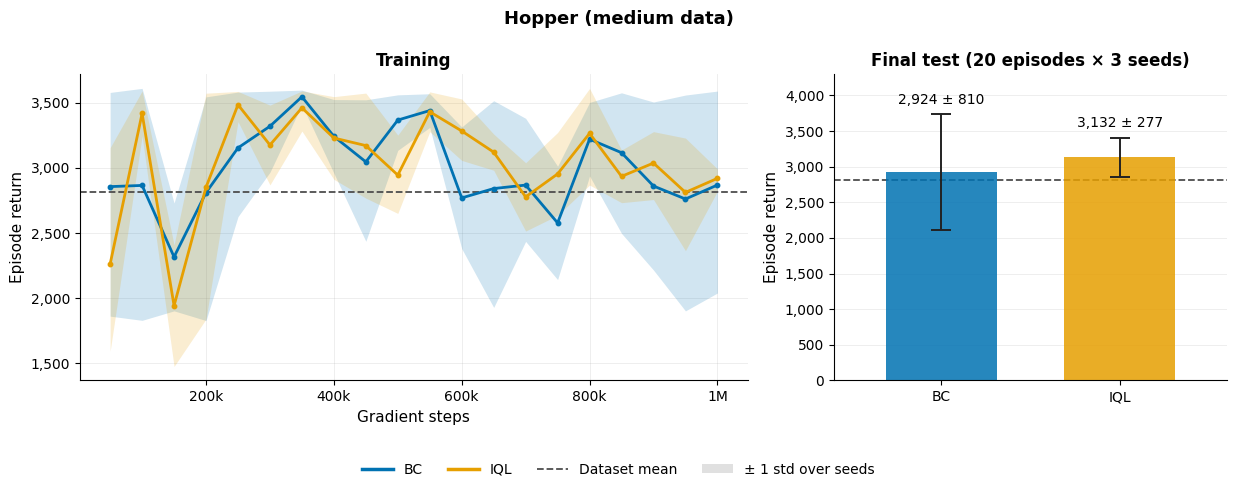

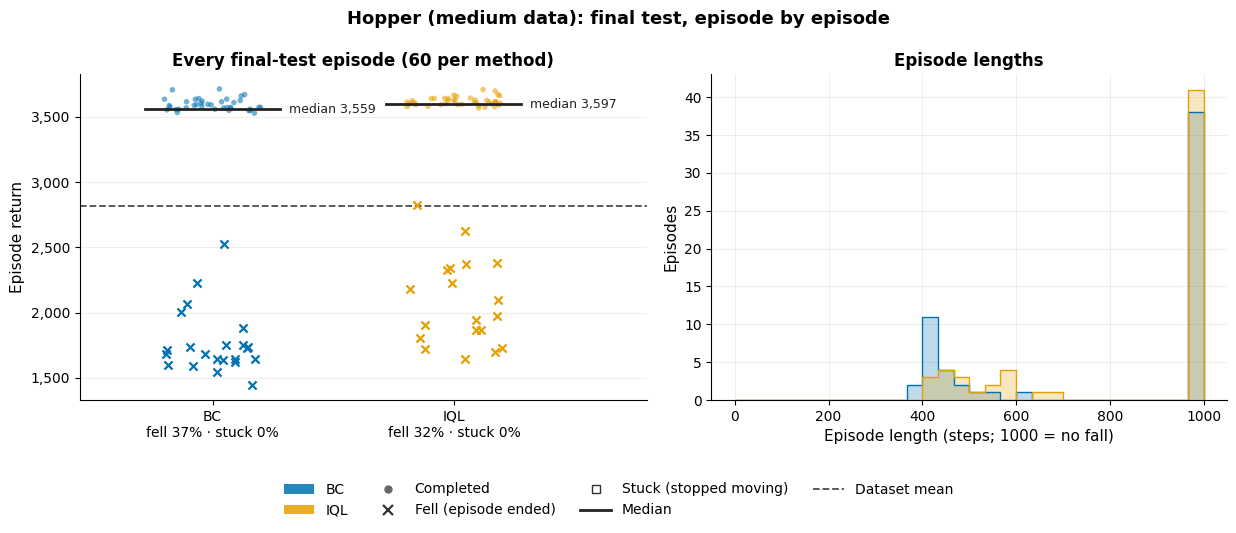

In [9]:
if RUN_OFFLINE:
    offline_res = evaluate_final(task, cfg, {"BC": bc_states, "IQL": iql_states}, {"BC": bc_log, "IQL": iql_log},
                                 pool, normalizer)
    summarize(offline_res)
    save_json(f"{RESULTS_DIR}/offline_results.json", offline_res)
    plotting.plot_offline_results(offline_res, save_path=f"{RESULTS_DIR}/figures/offline.png")
    plotting.plot_episode_outcomes(offline_res, save_path=f"{RESULTS_DIR}/figures/offline_episodes.png")

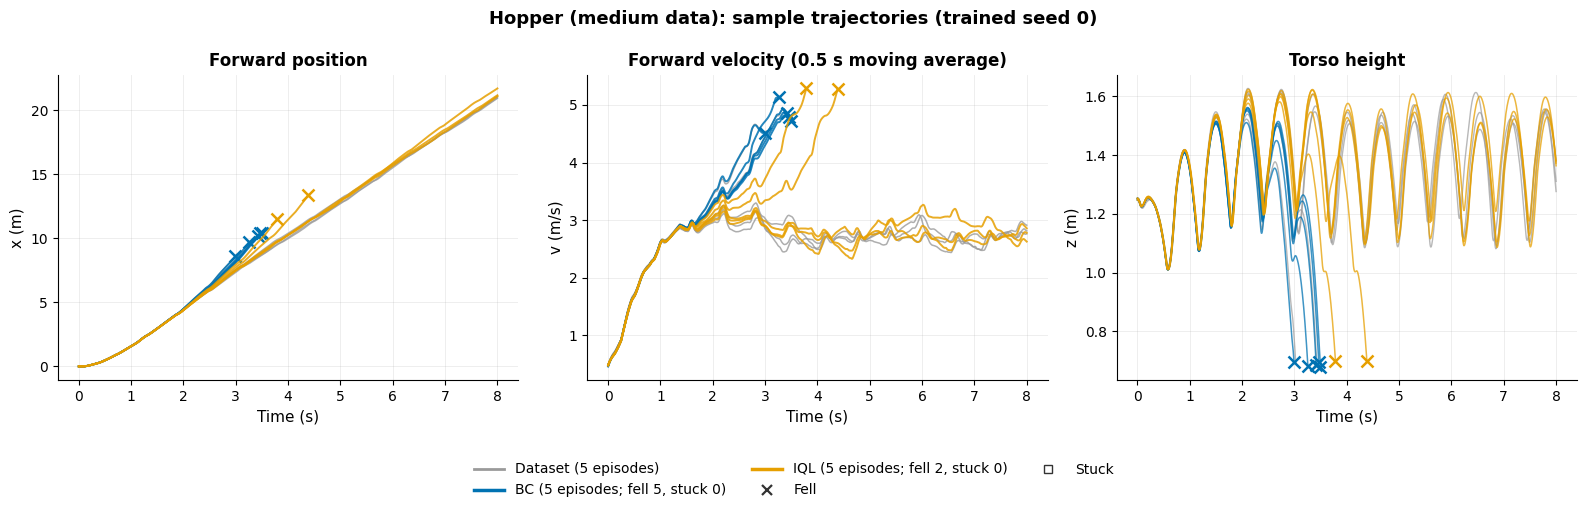

In [10]:
if RUN_OFFLINE:
    plotting.plot_mujoco_trajectories(task, {"BC": bc_states, "IQL": iql_states}, pool, normalizer,
                                      save_path=f"{RESULTS_DIR}/figures/offline_trajectories.png")

/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


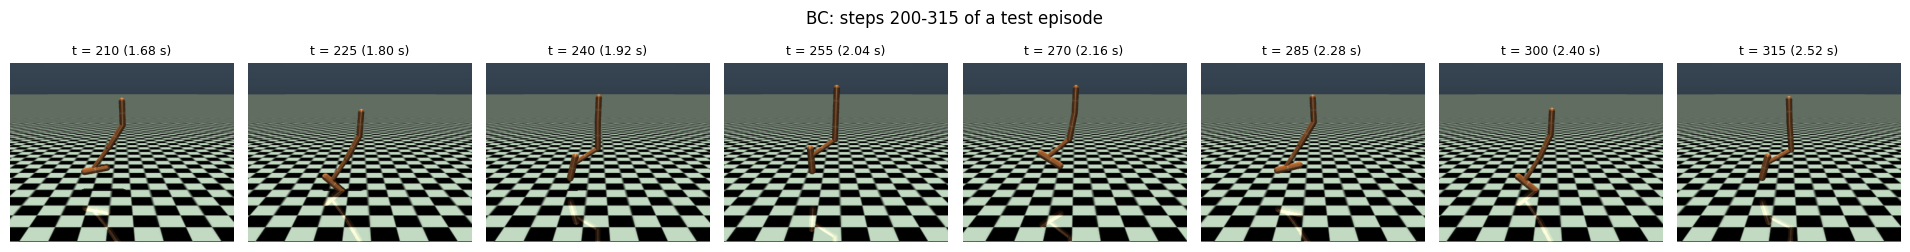

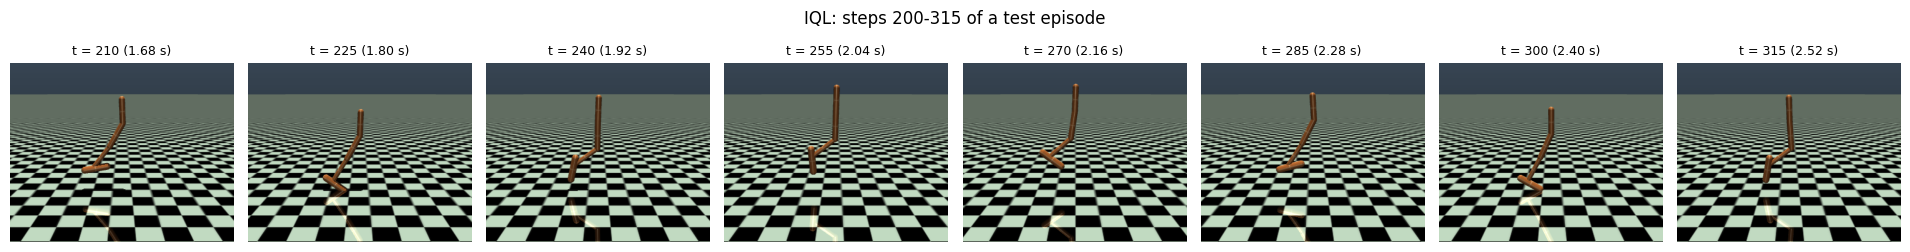

In [11]:
if RUN_OFFLINE:
    from offrl.video import plot_filmstrip
    try:
        for name, st in {"BC": bc_states, "IQL": iql_states}.items():
            plot_filmstrip(task, st, normalizer, title=name, save_path=f"{RESULTS_DIR}/figures/offline_filmstrip_{name.replace(' ', '_')}.png")
    except Exception as e:                      # rendering needs a GPU runtime on Colab (MUJOCO_GL=egl)
        print("Rendering is not available here:", e)

## 6. Checkpoint
Saves the configuration, the state normalizer and the BC and IQL networks (including optimizer states) to `checkpoints/<name>/offline.pkl`.

In [12]:
if RUN_OFFLINE:
    save_checkpoint(f"{CKPT_DIR}/offline.pkl", config=cfg, online=ONLINE, normalizer=normalizer.state_dict(),
                    bc_states=bc_states, iql_states=iql_states)

saved checkpoints/hopper_medium/offline.pkl (14.2 MB)


# Part 2: Online fine-tuning

The offline IQL networks are trained further with environment interaction, using the same losses (`offrl/algos/finetune.py`, following the official IQL implementation):

- **Data collection.** `envs_per_seed` environments per seed; actions $a = \operatorname{clip}\big(\mu_\theta(s) + T\,\sigma\,\varepsilon,\ -1,\ 1\big)$, $\varepsilon \sim \mathcal{N}(0, I)$, with $T$ = `explore_temperature`.
- **Labels.** Online transitions are labeled exactly as the offline data.
- **Replay.** One buffer per seed containing $\mathcal{D}_{\text{offline}} \cup \mathcal{D}_{\text{online}}$, sampled uniformly.
- **Optimization.** One update per environment step (`updates_per_step`); optimizers are re-initialized with a constant learning rate.

The log reports the evaluation metrics every `eval_every` online steps (step 0 is the offline policy) and statistics of the exploration episodes (`explore`). Checkpoints are written to `checkpoints/<name>/finetuned.pkl` after each evaluation.

## 7. Initialization from the offline IQL networks

In [13]:
if not RUN_OFFLINE:
    iql_states = ck["iql_states"]
offline_iql = iql_states
print("starting fine-tuning from:", "memory (Part 1)" if RUN_OFFLINE else f"{CKPT_DIR}/offline.pkl")
print("online settings:", ONLINE)

starting fine-tuning from: memory (Part 1)
online settings: {'online_steps': 300000, 'envs_per_seed': 4, 'chunk': 2000, 'updates_per_step': 1, 'explore_temperature': 1.0, 'reset_on_flip': False, 'eval_every': 50000, 'eval_episodes': 10, 'final_episodes': 20}


## 8. Fine-tuning
Evaluation metrics during fine-tuning (mean over seeds, ±1 std band); step 0 is the offline policy.

[FT] online step         0 | return [2991 2779 2986] (mean 2919) | pct_data [106.2 98.6 106.0] (mean 103.6) | explore: - | 4s
[FT] online step    50,000 | return [3416 3601 3556] (mean 3524) | pct_data [121.2 127.8 126.2] (mean 125.1) | explore: 538 episodes, return 989.6 | q_loss 0.319 V   139.96 | 125s
saved checkpoints/hopper_medium/finetuned.pkl (11.7 MB)
[FT] online step   100,000 | return [3194 3614 3624] (mean 3477) | pct_data [113.3 128.3 128.6] (mean 123.4) | explore: 529 episodes, return 1023.2 | q_loss 0.410 V   138.16 | 238s
saved checkpoints/hopper_medium/finetuned.pkl (11.7 MB)
[FT] online step   150,000 | return [3573 3556 3619] (mean 3582) | pct_data [126.8 126.2 128.4] (mean 127.1) | explore: 505 episodes, return 1090.0 | q_loss 0.443 V   137.02 | 352s
saved checkpoints/hopper_medium/finetuned.pkl (11.7 MB)
[FT] online step   200,000 | return [3593 3558 3600] (mean 3584) | pct_data [127.5 126.3 127.8] (mean 127.2) | explore: 461 episodes, return 1199.9 | q_loss 0.487 V

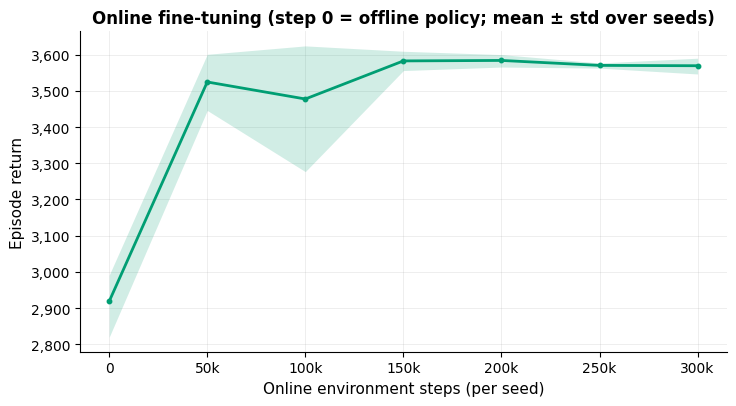

In [14]:
def save_progress(states, log):          # called after every evaluation
    save_checkpoint(f"{CKPT_DIR}/finetuned.pkl", config=cfg, online=ONLINE, normalizer=normalizer.state_dict(),
                    iql_states=states, log=log)

ft_states, ft_log = finetune(task, cfg, ONLINE, offline_iql, DATA, pool, normalizer, on_eval=save_progress)
save_json(f"{RESULTS_DIR}/finetune_log.json", ft_log)
plotting.plot_finetune(ft_log, list(task.curve_metrics), save_path=f"{RESULTS_DIR}/figures/finetune_curves.png")

### Offline and online learning curve
IQL evaluation metric over offline training followed by fine-tuning (shaded; one environment step corresponds to one gradient step). Reference lines: final BC result and dataset mean return. The offline curve is read from `results/<name>/offline_results.json`.

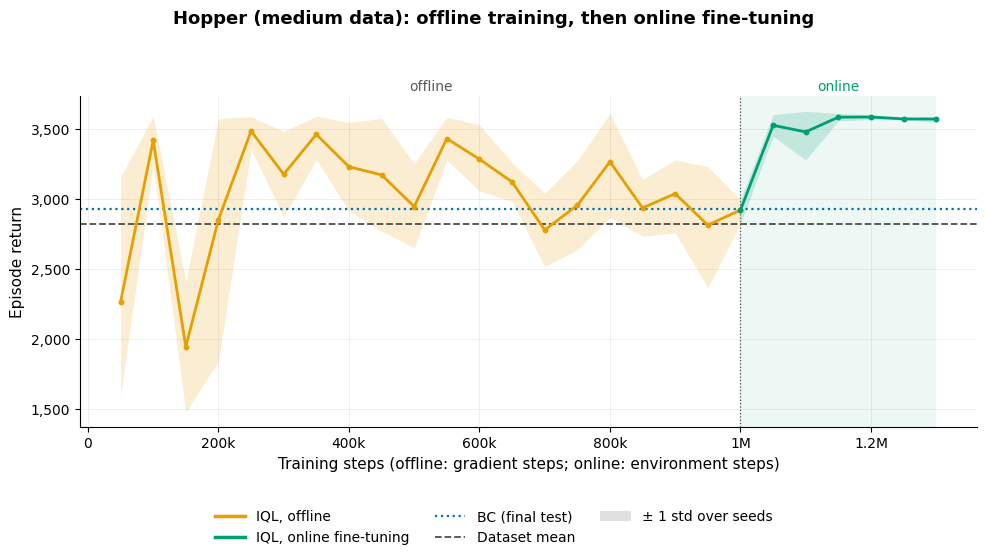

In [15]:
off_res = offline_res if RUN_OFFLINE else load_json(f"{RESULTS_DIR}/offline_results.json")
bc_final = float(np.mean([r["final"][task.primary] for r in off_res["methods"]["BC"]]))
refs = {task.primary: {"BC (final test)": bc_final}}
if task.kind == "mujoco":
    refs[task.primary]["dataset mean"] = task.data_return
plotting.plot_offline_online(off_res, ft_log, list(task.curve_metrics), refs=refs,
                             save_path=f"{RESULTS_DIR}/figures/offline_to_online.png")

## 9. Offline and fine-tuned policies
Final evaluation of both policies on the same episodes, with the figures of Section 5.

mujoco/hopper/medium-v0  (3 seeds, 20 test episodes per seed)
method                           return             pct_data                 fell                stuck
offline IQL              3,132 ± 277          111.2 ± 9.8           0.32 ± 0.16          0.00 ± 0.00  
fine-tuned IQL           3,581 ± 11           127.1 ± 0.4           0.02 ± 0.02          0.00 ± 0.00  
saved results/hopper_medium/finetune_results.json


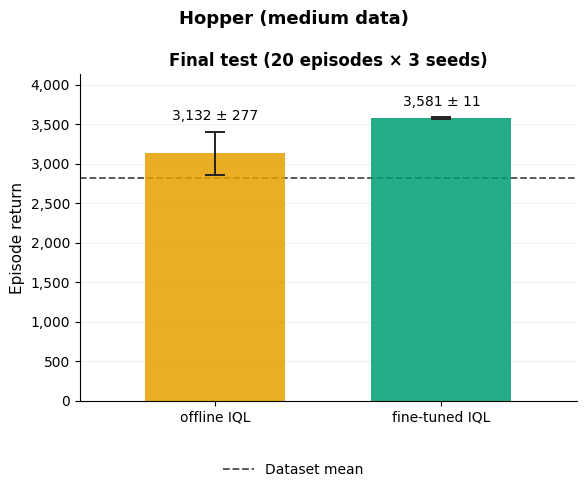

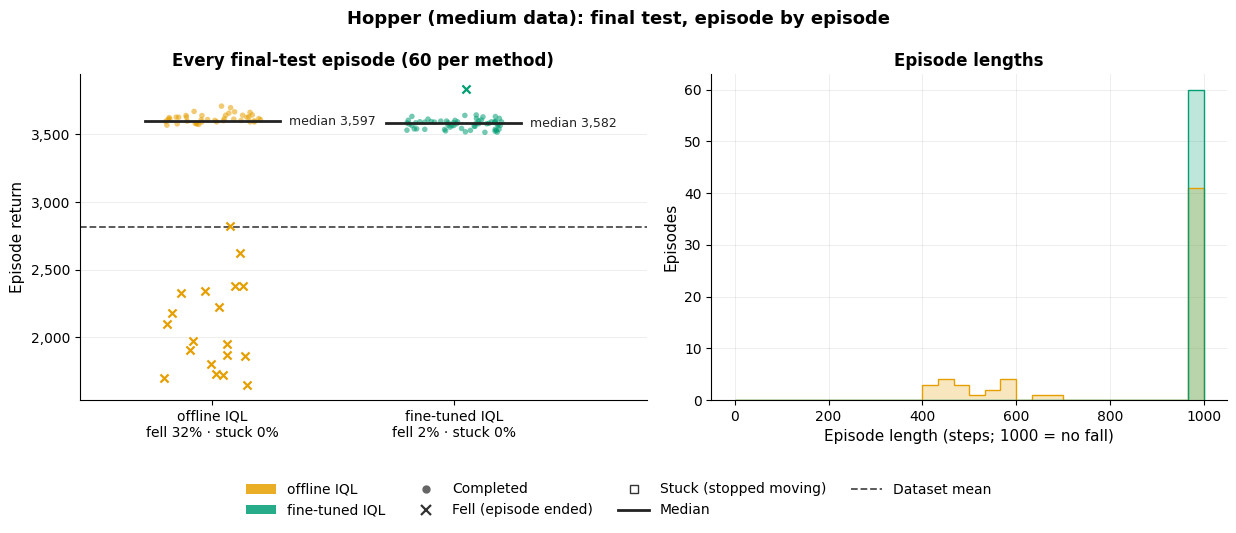

In [16]:
ft_res = evaluate_final(task, {**cfg, "final_episodes": ONLINE["final_episodes"]},
                        {"offline IQL": offline_iql, "fine-tuned IQL": ft_states}, None, pool, normalizer)
summarize(ft_res)
save_json(f"{RESULTS_DIR}/finetune_results.json", ft_res)
plotting.plot_offline_results(ft_res, save_path=f"{RESULTS_DIR}/figures/finetune_final.png")
plotting.plot_episode_outcomes(ft_res, save_path=f"{RESULTS_DIR}/figures/finetune_episodes.png")

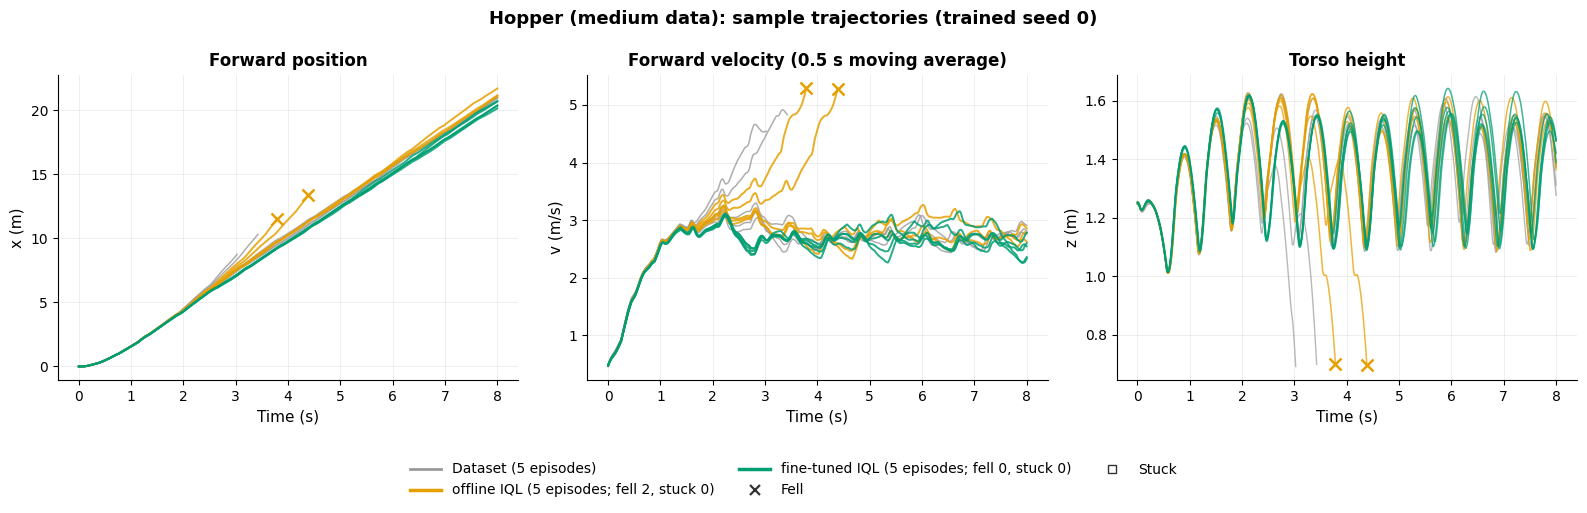

In [17]:
plotting.plot_mujoco_trajectories(task, {"offline IQL": offline_iql, "fine-tuned IQL": ft_states}, pool, normalizer,
                                  save_path=f"{RESULTS_DIR}/figures/finetune_trajectories.png")

/usr/local/lib/python3.13/dist-packages/minari/dataset/minari_dataset.py:204: UserWarning: Installed mujoco version 3.2.6 does not meet the requirement ==3.2.3.
We recommend to install the required version with `pip install "mujoco==3.2.3"`
  warnings.warn(


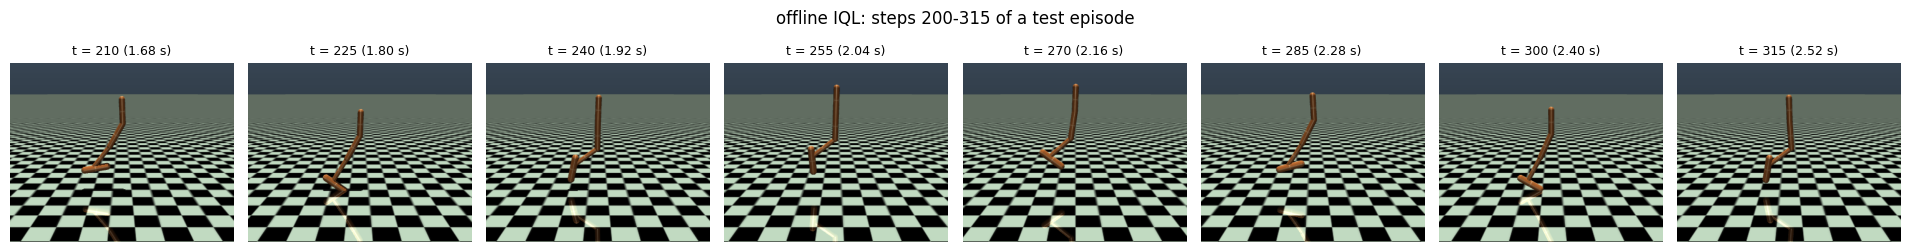

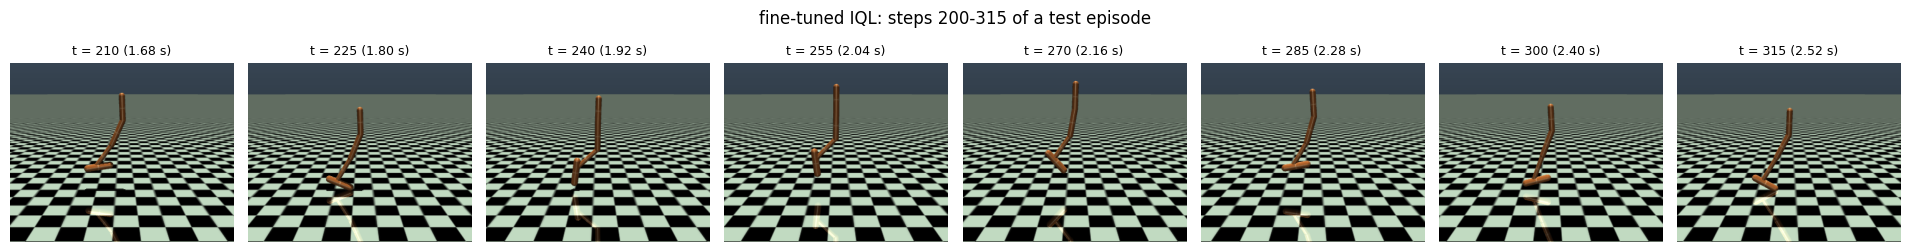

In [18]:
from offrl.video import plot_filmstrip
try:
    for name, st in {"offline IQL": offline_iql, "fine-tuned IQL": ft_states}.items():
        plot_filmstrip(task, st, normalizer, title=name, save_path=f"{RESULTS_DIR}/figures/finetune_filmstrip_{name.replace(' ', '_')}.png")
except Exception as e:                      # rendering needs a GPU runtime on Colab (MUJOCO_GL=egl)
    print("Rendering is not available here:", e)

## 10. Episode recording (optional)
Records one evaluation episode as a GIF (requires rendering). Side camera centered on the torso, approximately real time; `max_steps` and `camera_distance` adjust length and zoom. `seed_index` selects the trained seed.

In [19]:
from offrl.video import record_gif
from IPython.display import Image, display
gif_path, _ = record_gif(task, ft_states, normalizer, f"{RESULTS_DIR}/figures/fine_tuned.gif", seed_index=0)
display(Image(filename=gif_path))

ended at step 1000 | return 3538.2 -> results/hopper_medium/figures/fine_tuned.gif


[The animation is not stored in this notebook to keep its size small; a shortened copy is in media/hopper_medium.gif.]
